# 10x Visium BRCA Dataset with AnnData

### Gene set activity quantification with GESSO

This notebook uses the [10x Visium BRCA dataset](gesso_demo_10xvisium.ipynb) to demonstrate GESSO with AnnData, Scanpy, and Squidpy. The dataset contains 2,518 spots and 334 genes and is included in `demo_data/10xVisiumBRCA.h5ad`.

### Import the packages

Install GESSO and the optional tutorial dependencies from PyPI:

```bash
pip install 'gesso-py[tutorial]'
```

Run this notebook from the `docs` directory of the
[GESSO repository](https://github.com/YMa-lab/GESSO), which includes the BRCA data.

In [1]:
from pathlib import Path
import os
import warnings
import scanpy as sc
import squidpy as sq
import matplotlib.pyplot as plt
from IPython.display import display
from gesso import GESSO

project_directory = Path.cwd()
if not (project_directory / "demo_data").is_dir():
    project_directory = project_directory.parent

### Load the spatial transcriptomics data

Expression is stored as sparse counts in `X` and `layers["counts"]`, with spot and gene annotations in `obs` and `var`. Spatial coordinates are in `obsm["spatial"]`. This dataset contains array coordinates and no tissue image.

In [2]:
adata = sc.read_h5ad(project_directory / "demo_data" / "10xVisiumBRCA.h5ad")
display(adata)
display(adata.obs.head())

AnnData object with n_obs × n_vars = 2518 × 334
    obs: 'array_row', 'array_col', 'library_id'
    var: 'gene_symbols', 'feature_types'
    uns: 'dataset', 'spatial'
    obsm: 'spatial'
    varm: 'pathway_membership'
    layers: 'counts', None (.X)

,array_row,array_col,library_id
barcode,,,
GTAGACAACCGATGAA-1,7,55,BRCA
ACAGATTAGGTTAGTG-1,7,57,BRCA
TGGTATCGGTCTGTAT-1,7,59,BRCA
ATTATCTCGACAGATC-1,7,61,BRCA
TGAGATCAAATACTCA-1,7,63,BRCA


Next, retrieve the gene set membership table.

In [3]:
membership = adata.varm["pathway_membership"]
pathways = {
    pathway: membership.index[membership[pathway] == 1].tolist()
    for pathway in membership.columns
}
display(membership.head())

,KEGG_PATHWAYS_IN_CANCER,WP_INTERACTIONS_BETWEEN_IMMUNE_CELLS_AND_MICRORNAS_IN_TUMOR_MICROENVIRONMENT
gene,,
DVL1,1,0
PIK3CD,1,0
MTOR,1,0
CASP9,1,0
WNT4,1,0


### Use GESSO to compute gene set activity scores

Initialize the model directly from AnnData. Here we normalize raw counts; use `normalize_counts_method="none"` for data that is already normalized and log-transformed.

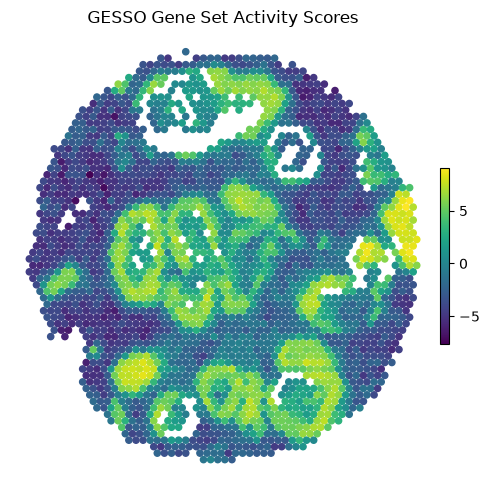

In [4]:
model = GESSO.from_anndata(
    adata,
    layer="counts",
    spatial_key="spatial",
    k=6,
    normalize_counts_method="normalize-log1p",
)
report = model.compute_gas(
    genesets_dict=pathways,
    beta=0.33,
    compute_method="cpu",
    n_jobs=1,
)
figure = report.plot_gas_spatial_map(
    geneset="KEGG_PATHWAYS_IN_CANCER",
    size=20,
    cmap="viridis",
    figsize=(5, 5),
)
display(figure)

You can retrieve scores and gene contributions from the report.

In [5]:
display(report.gas_df().head())
display(report.gene_contributions_df("KEGG_PATHWAYS_IN_CANCER").head(10))

,KEGG_PATHWAYS_IN_CANCER,WP_INTERACTIONS_BETWEEN_IMMUNE_CELLS_AND_MICRORNAS_IN_TUMOR_MICROENVIRONMENT
barcode,,
GTAGACAACCGATGAA-1,-1.138817,0.044478
ACAGATTAGGTTAGTG-1,-0.076075,-1.280936
TGGTATCGGTCTGTAT-1,-1.531171,-1.581284
ATTATCTCGACAGATC-1,-1.509820,-0.356816
TGAGATCAAATACTCA-1,-2.729211,-0.464503


,KEGG_PATHWAYS_IN_CANCER
ERBB2,0.209586
RARA,0.174633
PRKCA,0.174445
CDH1,0.168723
VEGFA,0.157951
TRAF4,0.156333
JUP,0.149140
EGF,0.142634
LAMA5,0.142438
CSF3R,0.140327


### Save results in AnnData

Store the scores in `obsm["gesso"]` and selected pathways in `obs` for plotting. Results are matched by spot ID.

In [6]:
report.write_to_anndata(adata, obs_columns=list(pathways))
cancer = "gesso:KEGG_PATHWAYS_IN_CANCER"
immune = (
    "gesso:WP_INTERACTIONS_BETWEEN_IMMUNE_CELLS_AND_MICRORNAS_IN_TUMOR_MICROENVIRONMENT"
)
display(adata.obsm["gesso"].head())

,KEGG_PATHWAYS_IN_CANCER,WP_INTERACTIONS_BETWEEN_IMMUNE_CELLS_AND_MICRORNAS_IN_TUMOR_MICROENVIRONMENT
barcode,,
GTAGACAACCGATGAA-1,-1.138817,0.044478
ACAGATTAGGTTAGTG-1,-0.076075,-1.280936
TGGTATCGGTCTGTAT-1,-1.531171,-1.581284
ATTATCTCGACAGATC-1,-1.509820,-0.356816
TGAGATCAAATACTCA-1,-2.729211,-0.464503


### Plot with Scanpy or Squidpy

The same scores can also be plotted using Scanpy or Squidpy.

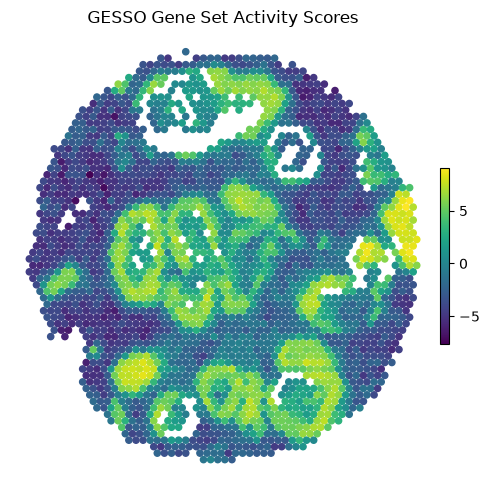

In [7]:
fig, ax = plt.subplots(figsize=(5, 5))
sc.pl.embedding(
    adata,
    basis="spatial",
    color=cancer,
    size=20,
    cmap="viridis",
    frameon=False,
    colorbar_loc=None,
    ax=ax,
    show=False,
    marker="o",
    sort_order=False,
)
ax.collections[0].set_edgecolor("face")
ax.collections[0].set_linewidth(1)
ax.set_aspect("auto")
ax.set_title("GESSO Gene Set Activity Scores")
fig.colorbar(ax.collections[0], ax=ax, fraction=0.02, pad=0.01)
fig.tight_layout()
plt.close(fig)
display(fig)

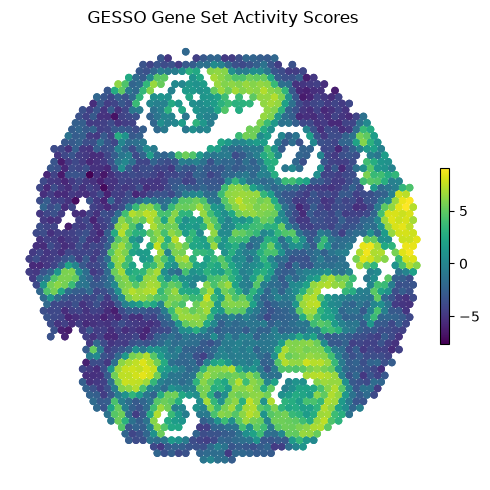

In [8]:
fig, ax = plt.subplots(figsize=(5, 5))
with warnings.catch_warnings():
    # Squidpy currently calls AnnData's deprecated obs_vector method.
    warnings.filterwarnings(
        "ignore",
        message="The method obs_vector is deprecated.*",
        category=FutureWarning,
        module=r"squidpy\.pl\._spatial_utils",
    )
    sq.pl.spatial_scatter(
        adata,
        color=cancer,
        library_key="library_id",
        img=False,
        shape=None,
        size=20,
        cmap="viridis",
        frameon=False,
        colorbar=False,
        ax=ax,
        return_ax=True,
        marker="o",
    )
ax.collections[0].set_edgecolor("face")
ax.collections[0].set_linewidth(1)
ax.set_aspect("auto")
ax.invert_yaxis()
ax.set_title("GESSO Gene Set Activity Scores")
fig.colorbar(ax.collections[0], ax=ax, fraction=0.02, pad=0.01)
fig.tight_layout()
plt.close(fig)
display(fig)

### Save the AnnData file

Save the expression data, spatial coordinates, and GESSO results together.

In [9]:
output_directory = Path(
    os.environ.get(
        "GESSO_TUTORIAL_OUTPUT_DIR",
        project_directory / "docs" / "_build" / "anndata_tutorial",
    )
)
output_directory.mkdir(parents=True, exist_ok=True)
adata.write_h5ad(output_directory / "10xVisiumBRCA-gesso.h5ad", compression="gzip")